# What is Machine Learning?

> The field of study that gives computers the ability to learn without explicitly being programmed. - Arthur Samuel (1950s), founder of Machine Learning

> The process of using computers to detect patterns in massive datasets and then make predictions based on what the computer learns from those patterns. - US Department of Energy (https://www.energy.gov/science/doe-explainsmachine-learning)

> Building mathematical models to help understand data. - JakeVanderPlas (2016), our textbook

If you look at definitions for "Machine Learning", you will pick up on two themes: 
- Machines doing things without being explicitly told to do things
- Identifying patterns to make future predictions

Arthur Samuel's first machine learning algorithm involved a computer playing Checkers. Rather than writing specific rules for the computer to follow like "Find all pieces that can be moved without being taken, then move the piece that is furthest forward on the board.", he created a scoring function based on the position of the board at any given time. The computer was told to optimize the value of this function - so its next move should be the one that provides the highest score. He continued to improve his scoring function until it could compete with actual human players. 

This algorithm encompasses the two themes of machine learning: the algorithm gave a score that guided action without explicitly telling it what to do and the scoring function WAS the pattern used to make future predictions. 

# Categories of Machine Learning

While our course will focus on a couple categories of Machine Learning, it is important to recognize all four general categories. Categories for the general machine learning models are based on the data they use or how parameters are changed to learn in the model. 

## Supervised Learning

In Supervised Learning, we have a set of data (predictor variables) and the associated thing we are trying to predict (response variable). We find a pattern between the predictor variables and the response variable that we can then use to predict future responses. This is split into two types based on what we are trying to predict.

### Classification Supervised Learning

Our goal is to predict a class. For example, a spam detector trained on predictor variables such as email name, title, misspellings tries to classify an email as "Spam" or "Not Spam". 

Our book shows a generic example where we can use predictive features $f1$ and $f2$ as well as their response label (in this case blue or red) to create a cutoff in the 2d space that will predict all $(f1, f2)$ points that land on the bottom to be a "red" response and all $(f1, f2)$ points that land in the top to be a "blue" response. 

I've also included a different classification method called a Decision Tree. This can be used to deal with highly complex relationships like classifying animals. 

#### Necessary Code for Classification Example

In [4]:
# Necessary imports and functions
import numpy as np
from matplotlib import pyplot as plt

# common plot formatting for below
def format_plot(ax, title):
    ax.xaxis.set_major_formatter(plt.NullFormatter())
    ax.yaxis.set_major_formatter(plt.NullFormatter())
    ax.set_xlabel('feature 1', color='gray')
    ax.set_ylabel('feature 2', color='gray')
    ax.set_title(title, color='gray')

from sklearn.datasets import make_blobs
from sklearn.svm import SVC

# create 50 separable points
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)

# fit the support vector classifier model
clf = SVC(kernel='linear')
clf.fit(X, y)

# create some new points to predict
X2, _ = make_blobs(n_samples=80, centers=2,
                   random_state=0, cluster_std=0.80)
X2 = X2[50:]

# predict the labels
y2 = clf.predict(X2)

#### Classification Example 1

(np.float64(-1.0), np.float64(4.0), np.float64(-2.0), np.float64(7.0))

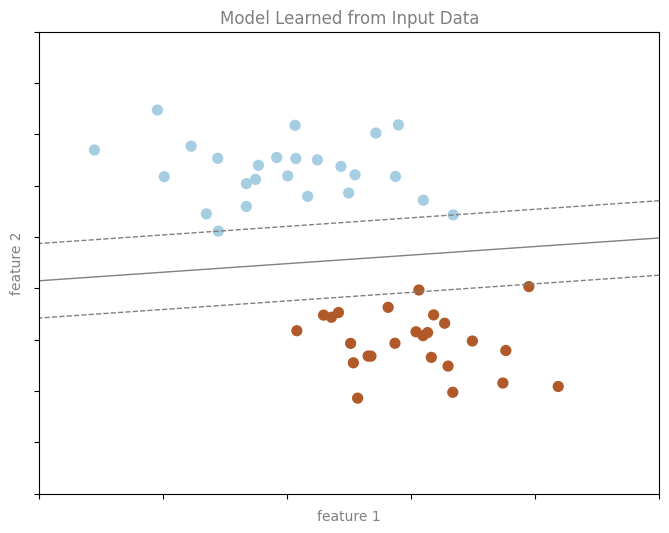

In [7]:
# Get contours describing the model
xx = np.linspace(-1, 4, 10)
yy = np.linspace(-2, 7, 10)
xy1, xy2 = np.meshgrid(xx, yy)
Z = np.array([clf.decision_function([t])
              for t in zip(xy1.flat, xy2.flat)]).reshape(xy1.shape)

# plot points and model
fig, ax = plt.subplots(figsize=(8, 6))
line_style = dict(levels = [-1.0, 0.0, 1.0],
                  linestyles = ['dashed', 'solid', 'dashed'],
                  colors = 'gray', linewidths=1)
point_style = dict(cmap='Paired', s=50)
ax.scatter(X[:, 0], X[:, 1], c=y, **point_style)
ax.contour(xy1, xy2, Z, **line_style)

# format plot
format_plot(ax, 'Model Learned from Input Data')
ax.axis([-1, 4, -2, 7])

#### Classification Example 2

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

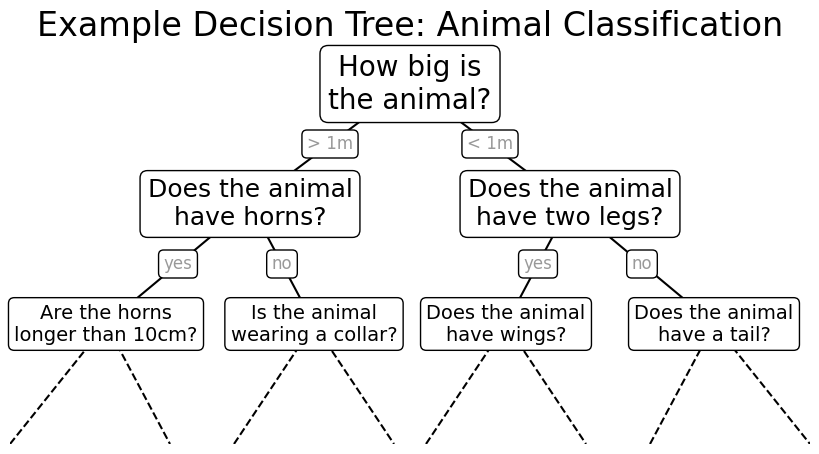

In [27]:
fig = plt.figure(figsize=(10, 4))
ax = fig.add_axes([0, 0, 0.8, 1], frameon=False, xticks=[], yticks=[])
ax.set_title('Example Decision Tree: Animal Classification', size=24)

def text(ax, x, y, t, size=20, **kwargs):
    ax.text(x, y, t,
            ha='center', va='center', size=size,
            bbox=dict(boxstyle='round', ec='k', fc='w'), **kwargs)

text(ax, 0.5, 0.9, "How big is\nthe animal?", 20)
text(ax, 0.3, 0.6, "Does the animal\nhave horns?", 18)
text(ax, 0.7, 0.6, "Does the animal\nhave two legs?", 18)
text(ax, 0.12, 0.3, "Are the horns\nlonger than 10cm?", 14)
text(ax, 0.38, 0.3, "Is the animal\nwearing a collar?", 14)
text(ax, 0.62, 0.3, "Does the animal\nhave wings?", 14)
text(ax, 0.88, 0.3, "Does the animal\nhave a tail?", 14)

text(ax, 0.4, 0.75, "> 1m", 12, alpha=0.4)
text(ax, 0.6, 0.75, "< 1m", 12, alpha=0.4)

text(ax, 0.21, 0.45, "yes", 12, alpha=0.4)
text(ax, 0.34, 0.45, "no", 12, alpha=0.4)

text(ax, 0.66, 0.45, "yes", 12, alpha=0.4)
text(ax, 0.79, 0.45, "no", 12, alpha=0.4)

ax.plot([0.3, 0.5, 0.7], [0.6, 0.9, 0.6], '-k')
ax.plot([0.12, 0.3, 0.38], [0.3, 0.6, 0.3], '-k')
ax.plot([0.62, 0.7, 0.88], [0.3, 0.6, 0.3], '-k')
ax.plot([0.0, 0.12, 0.20], [0.0, 0.3, 0.0], '--k')
ax.plot([0.28, 0.38, 0.48], [0.0, 0.3, 0.0], '--k')
ax.plot([0.52, 0.62, 0.72], [0.0, 0.3, 0.0], '--k')
ax.plot([0.8, 0.88, 1.0], [0.0, 0.3, 0.0], '--k')
ax.axis([0, 1, 0, 1])

### Regression Supervised Learning

Our goal is to predict a continuous value. For example, based on predictor variables such as BMI, steps per day, family history of hereditary diseases, and cholesterol level, we can create a "heart health score" that attempts to measure how healthy your heart is. 

Rather than the examples in the "What is Machine Learning?" section of our textbook, let's look ahead to two generic regression examples.

#### Code Necessary for Regression Example

In [9]:
import numpy as np

def make_data(N=30, err=0.8, rseed=1):
    # randomly sample the data
    rng = np.random.RandomState(rseed)
    X = rng.rand(N, 1) ** 2
    y = 10 - 1. / (X.ravel() + 0.1)
    if err > 0:
        y += err * rng.randn(N)
    return X, y

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

def PolynomialRegression(degree=2, **kwargs):
    return make_pipeline(PolynomialFeatures(degree),
                         LinearRegression(**kwargs))

#### Regression Example

Text(0.5, 1.0, 'High-variance model: Overfits the data')

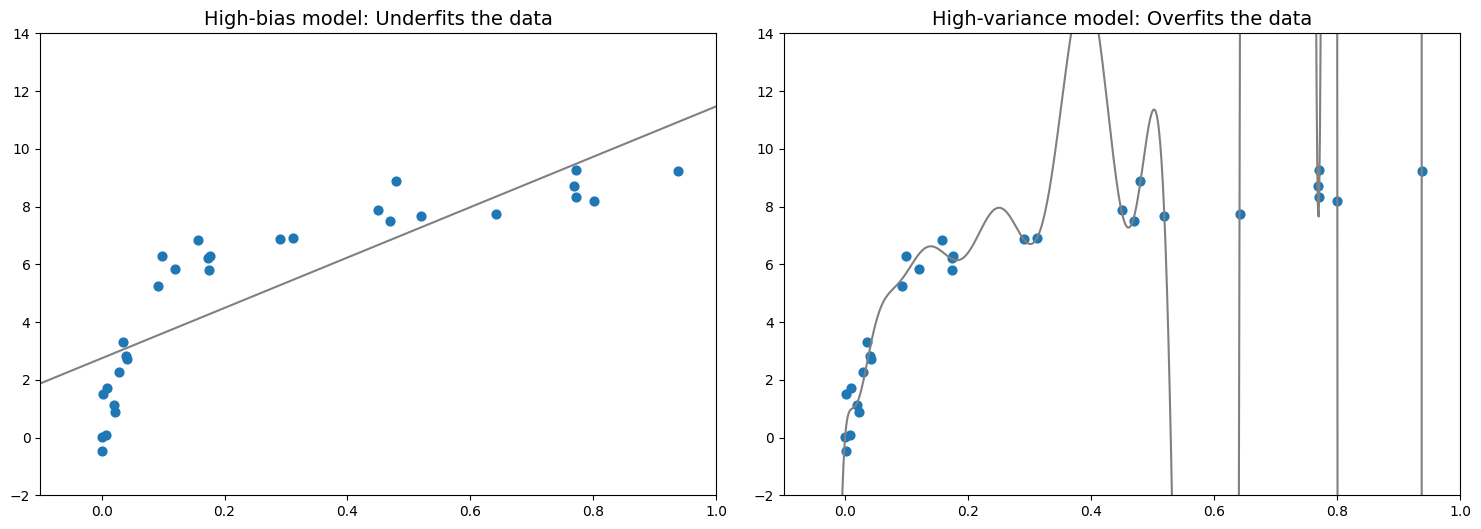

In [10]:
X, y = make_data()
xfit = np.linspace(-0.1, 1.0, 1000)[:, None]
model1 = PolynomialRegression(1).fit(X, y)
model20 = PolynomialRegression(20).fit(X, y)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

ax[0].scatter(X.ravel(), y, s=40)
ax[0].plot(xfit.ravel(), model1.predict(xfit), color='gray')
ax[0].axis([-0.1, 1.0, -2, 14])
ax[0].set_title('High-bias model: Underfits the data', size=14)

ax[1].scatter(X.ravel(), y, s=40)
ax[1].plot(xfit.ravel(), model20.predict(xfit), color='gray')
ax[1].axis([-0.1, 1.0, -2, 14])
ax[1].set_title('High-variance model: Overfits the data', size=14)

In this example we have the same data being fitted to two different regression models: linear and polynomial. 

Consider for yourself - which model do you think makes the **best** prediction for future data points?

## Unsupervised Learning

In Unsupervised Learning, we do not have labeled response data. Our goal is to learn how to create labeled responses. This is commonly subdivided into clustering and dimensionality reduction. Learning occurs through our choices of (a) how many categories to split the data into and (b) definition of a function for "closeness" of data. 

### Clustering Unsupervised Learning

Sometimes, data appears to "physically" collect together. We can use this closeness-in-distance to create a classification, saying all data within some distance of a cluster point belongs to the same class. We then just need to learn what our cluster points are for each class.

In the example below, you can see that the process for creating the 3 clusters moves the cluster point of each color so that it eventually becomes the middle value for the class of points. This is our first look at the iterative process the machine learns through!

![K-Means Clustering GIF Example](./Images/K-means_convergence.gif)

Source: https://en.wikipedia.org/wiki/File:K-means_convergence.gif

### Dimensionality Reduction Unsupervised Learning

In many cases, we don't want all of the detail that is provided in our raw data. For example, human brains can do an incredible job flitering out unnecessary data to identify images. Later in the course we will talk about how to find the "necessary" data, but we can look at an example of filtering out noise in an image of numbers. 

#### Necessary Code for Dimensionality Reduction Example

In [24]:
from sklearn.datasets import load_digits
digits = load_digits()
digits.data.shape

def plot_digits(data):
    fig, axes = plt.subplots(4, 10, figsize=(10, 4),
                             subplot_kw={'xticks':[], 'yticks':[]},
                             gridspec_kw=dict(hspace=0.1, wspace=0.1))
    for i, ax in enumerate(axes.flat):
        ax.imshow(data[i].reshape(8, 8),
                  cmap='binary', interpolation='nearest',
                  clim=(0, 16))

from sklearn.decomposition import PCA
pca = PCA(2)  # project from 64 to 2 dimensions
projected = pca.fit_transform(digits.data)

#### Dimensionality Reduction Example

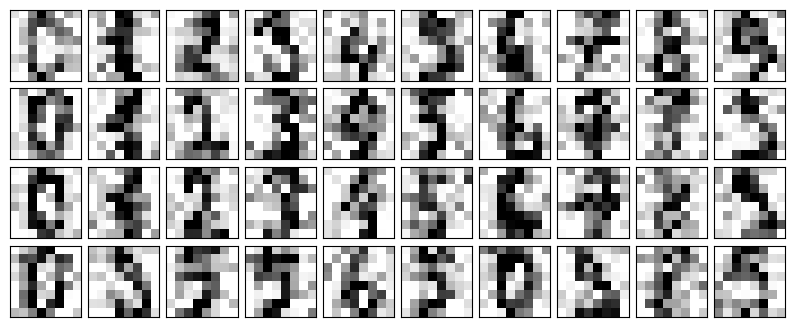

In [25]:
np.random.seed(42)
noisy = np.random.normal(digits.data, 4)
plot_digits(noisy)

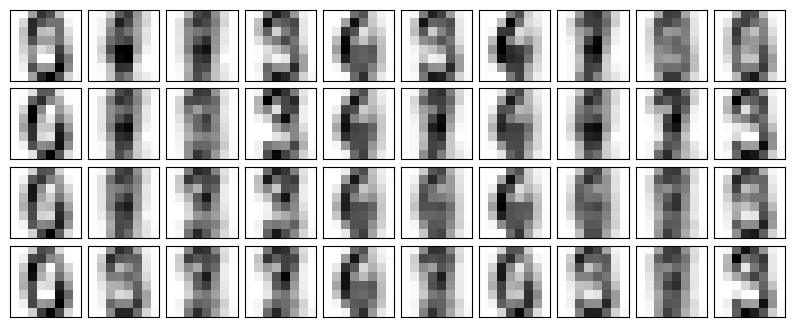

In [26]:
components = pca.transform(noisy)
filtered = pca.inverse_transform(components)
plot_digits(filtered)

## Reinforcement Learning

Reinforcement Learning is when an "intelligent agent" takes actions to maximize a reward signal. Learning occurs through a reward function output for any series of actions. If this sounds like the behavioral research of training rats to complete a maze through rewards (cheese at the end) you'd be right! Reinforcement Learning through Operant Conditioning attempts to increase behavior by providing a pleasant stimulus (positive reinforcement) or removing an unpleasant stimulus (negative reinforcement). In Machine Reinforcement Learning, the goal is to maximize the pleasant stimulus (e.g., maximize score when scoring is "good") or minimize the unpleasant stimulus (e.g., an autonomous car minimizing hitting a wall when score from hitting a wall is "bad"). 

The original Checkers algorithm by Arthur Samuel in the 1950s is an excellent example of Reinforcement Learning. In fact, it is common to use board games and video games as a benchmark for different types of artificial intelligence due to how well-defined the games are. 

Since our course will not look at Reinforcement Learning, interested students can instead check out this 16:26 minute video that provides an overview of Reinforcement Learning: https://www.youtube.com/watch?v=JgvyzIkgxF0. If you do review the video, you'll hear about Supervised, Unsupervised, and Deep Learning. You'll see that it is a fair bit more challenging to set up than the Supervised and Unsupervised Learning methods we've discussed so far, which is why we'll save it for a more advanced course. 

## Deep Learning

Last, but in now way least, is "Deep" Learning. This involves the use of neural networks, which are computation models based on how neurons in a brain work. Refer to the image of a neural network below. 

- Each neuron in the "Hidden Layer 1" receives 1 or more input signals from the "Input Layer".
- Each neuron has its own computation function, multiplying the signal values by a weight and adding a bias (error). 
- The neuron's result goes through an activation function, deciding if the neuron activates (sending a 1 to connected neurons) or not (sending a 0 to connected neurons). 
- These 0/1 signals from "Hidden Layer 1" are then sent to "Hidden Layer 2", where those neurons use their individual computation functions. 
- The "Hidden Layer 2" neuron results then go through an activation function, deciding if they activate or not.
- These 0/1 signals from Hidden Layer 2 are then sent to the "Output Layer", which decides on an action.

Learning occurs by adjusting the weights of the network to reduce error before the next round of activation. This process can occur thousands or even millions of times before the model becomes accurate! Like Reinforcement Learning, this is far too complex a model to start with and will be saved for more advanced courses.

At its core, LLMs like ChatGPT are Deep Learning models trained on billions of neurons. ChatGPT 3.5 has approximately 175 billion parameters (parameters are the adjustable values like the signal weights and bias values within each neuron) while it is estimated ChatGPT 4.0 has approximately 1.7 trillion parameters. For context, a human brain has on average 86 billion neurons. 

### Necessary Code for Neural Network Image 

In [31]:
# Taken from: https://stackoverflow.com/questions/29888233/how-to-visualize-a-neural-network

from matplotlib import pyplot
from math import cos, sin, atan

class Neuron():
    def __init__(self, x, y):
        self.x = x
        self.y = y

    def draw(self, neuron_radius):
        circle = pyplot.Circle((self.x, self.y), radius=neuron_radius, fill=False)
        pyplot.gca().add_patch(circle)


class Layer():
    def __init__(self, network, number_of_neurons, number_of_neurons_in_widest_layer):
        self.vertical_distance_between_layers = 6
        self.horizontal_distance_between_neurons = 2
        self.neuron_radius = 0.5
        self.number_of_neurons_in_widest_layer = number_of_neurons_in_widest_layer
        self.previous_layer = self.__get_previous_layer(network)
        self.y = self.__calculate_layer_y_position()
        self.neurons = self.__intialise_neurons(number_of_neurons)

    def __intialise_neurons(self, number_of_neurons):
        neurons = []
        x = self.__calculate_left_margin_so_layer_is_centered(number_of_neurons)
        for iteration in range(number_of_neurons):
            neuron = Neuron(x, self.y)
            neurons.append(neuron)
            x += self.horizontal_distance_between_neurons
        return neurons

    def __calculate_left_margin_so_layer_is_centered(self, number_of_neurons):
        return self.horizontal_distance_between_neurons * (self.number_of_neurons_in_widest_layer - number_of_neurons) / 2

    def __calculate_layer_y_position(self):
        if self.previous_layer:
            return self.previous_layer.y + self.vertical_distance_between_layers
        else:
            return 0

    def __get_previous_layer(self, network):
        if len(network.layers) > 0:
            return network.layers[-1]
        else:
            return None

    def __line_between_two_neurons(self, neuron1, neuron2):
        angle = atan((neuron2.x - neuron1.x) / float(neuron2.y - neuron1.y))
        x_adjustment = self.neuron_radius * sin(angle)
        y_adjustment = self.neuron_radius * cos(angle)
        line = pyplot.Line2D((neuron1.x - x_adjustment, neuron2.x + x_adjustment), (neuron1.y - y_adjustment, neuron2.y + y_adjustment))
        pyplot.gca().add_line(line)

    def draw(self, layerType=0):
        for neuron in self.neurons:
            neuron.draw( self.neuron_radius )
            if self.previous_layer:
                for previous_layer_neuron in self.previous_layer.neurons:
                    self.__line_between_two_neurons(neuron, previous_layer_neuron)
        # write Text
        x_text = self.number_of_neurons_in_widest_layer * self.horizontal_distance_between_neurons
        if layerType == 0:
            pyplot.text(x_text, self.y, 'Input Layer', fontsize = 12)
        elif layerType == -1:
            pyplot.text(x_text, self.y, 'Output Layer', fontsize = 12)
        else:
            pyplot.text(x_text, self.y, 'Hidden Layer '+str(layerType), fontsize = 12)

class NeuralNetwork():
    def __init__(self, number_of_neurons_in_widest_layer):
        self.number_of_neurons_in_widest_layer = number_of_neurons_in_widest_layer
        self.layers = []
        self.layertype = 0

    def add_layer(self, number_of_neurons ):
        layer = Layer(self, number_of_neurons, self.number_of_neurons_in_widest_layer)
        self.layers.append(layer)

    def draw(self):
        pyplot.figure()
        for i in range( len(self.layers) ):
            layer = self.layers[i]
            if i == len(self.layers)-1:
                i = -1
            layer.draw( i )
        pyplot.axis('scaled')
        pyplot.axis('off')
        pyplot.title( 'Neural Network architecture', fontsize=15 )
        pyplot.show()

class DrawNN():
    def __init__( self, neural_network ):
        self.neural_network = neural_network

    def draw( self ):
        widest_layer = max( self.neural_network )
        network = NeuralNetwork( widest_layer )
        for l in self.neural_network:
            network.add_layer(l)
        network.draw()

### Image of a Neural Network

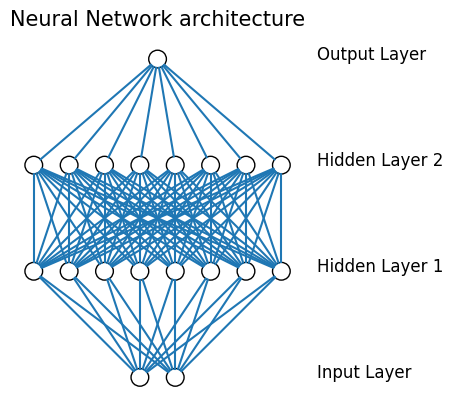

In [32]:
network = DrawNN( [2,8,8,1] ).draw()